# 09 · Data window, quality and normalisation (Phase D)
Rebuild the dataset from the raw CWC/IMD/GSI files, verify every data contract, pick the study window where sources meet, and fit normalisation parameters on the training split only.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

## 1. Rebuild cleaned → hourly → final table

In [2]:
from src.pipeline import run_objective_2_pipeline
base = run_objective_2_pipeline()
base.shape


--- 1. Generating Master District Crosswalk ---

--- 2. Executing Source Data Cleaning ---


Rainfall quality flags: {'valid': 38930, 'faulty_station': 6111, 'sentinel': 807, 'implausible': 458, 'negative_invalid': 73}
Quarantined (faulty) gauges: ['Purola_1', 'Roorkee_2', 'Yamuna Colony']
Cleaned rainfall saved: 40,640 records at E:\Harsh\VIT\TY\Sem V\DS\Course Project\Project\data\processed\cleaned\rainfall_cleaned.parquet


Cleaned river discharge saved: 90,303 records at E:\Harsh\VIT\TY\Sem V\DS\Course Project\Project\data\processed\cleaned\discharge_cleaned.parquet
Cleaned landslides saved: 5,417 records at E:\Harsh\VIT\TY\Sem V\DS\Course Project\Project\data\processed\cleaned\landslide_cleaned.parquet
Cleaned flood inventory saved: 334 district-event records at E:\Harsh\VIT\TY\Sem V\DS\Course Project\Project\data\processed\cleaned\flood_inventory_cleaned.parquet
Cleaned district supporting data saved: 13 districts at E:\Harsh\VIT\TY\Sem V\DS\Course Project\Project\data\processed\cleaned\district_supporting_cleaned.parquet
All datasets cleaned and stored in data/processed/cleaned/.

--- 3. Ingesting Cleaned Sources ---

--- 4. Computing Rainfall Features (Backward Rolling & API) ---


  dropping Purola_1: no valid readings (quarantined gauge)
  dropping Roorkee_2: no valid readings (quarantined gauge)
  dropping Yamuna Colony: no valid readings (quarantined gauge)



--- 5. Computing Discharge Features (Deltas & Anomalies) ---


...


--- 9. Computing Past-Only Historical Flood Exposure ---



--- 10. Constructing 24h Forward Target & Checking Leakage ---


Zero-future-leakage assertion verified successfully.

--- 11. Defining Chronological Train/Test Partition ---

--- 12. Exporting Final ML-Ready Table ---



SUCCESS! Master ML Dataset saved:
Parquet: E:\Harsh\VIT\TY\Sem V\DS\Course Project\Project\data\processed\final\uttarakhand_flash_flood_ml_dataset.parquet (518,304 rows x 61 columns)
CSV:     E:\Harsh\VIT\TY\Sem V\DS\Course Project\Project\data\processed\final\uttarakhand_flash_flood_ml_dataset.csv
Labelled rows: 126,904
Unlabelled (replay) rows: 391,400
Target distribution (flood_event_24h = 1): 895 records


(518304, 61)

## 2. Coverage: where do the datasets meet?

         rain_stations  discharge_gauges  flood_events
2021-02              0                 0             1
2021-05              0                 0             1
2021-07              0                 0             3
2021-08              0                 0             1
2021-10              0                 0             8
2022-01              1                 0             0
2022-06              1                 0             0
2022-07              4                 0             1
2022-08              6                 1             4
2022-09              8                 0             2
2022-10              8                 0             0
2022-11              5                 0             0
2022-12              9                 0             0
2023-01             22                 0             0
2023-02             14                 0             0
2023-03             21                 0             0
2023-04             24                 1             0
2023-05   

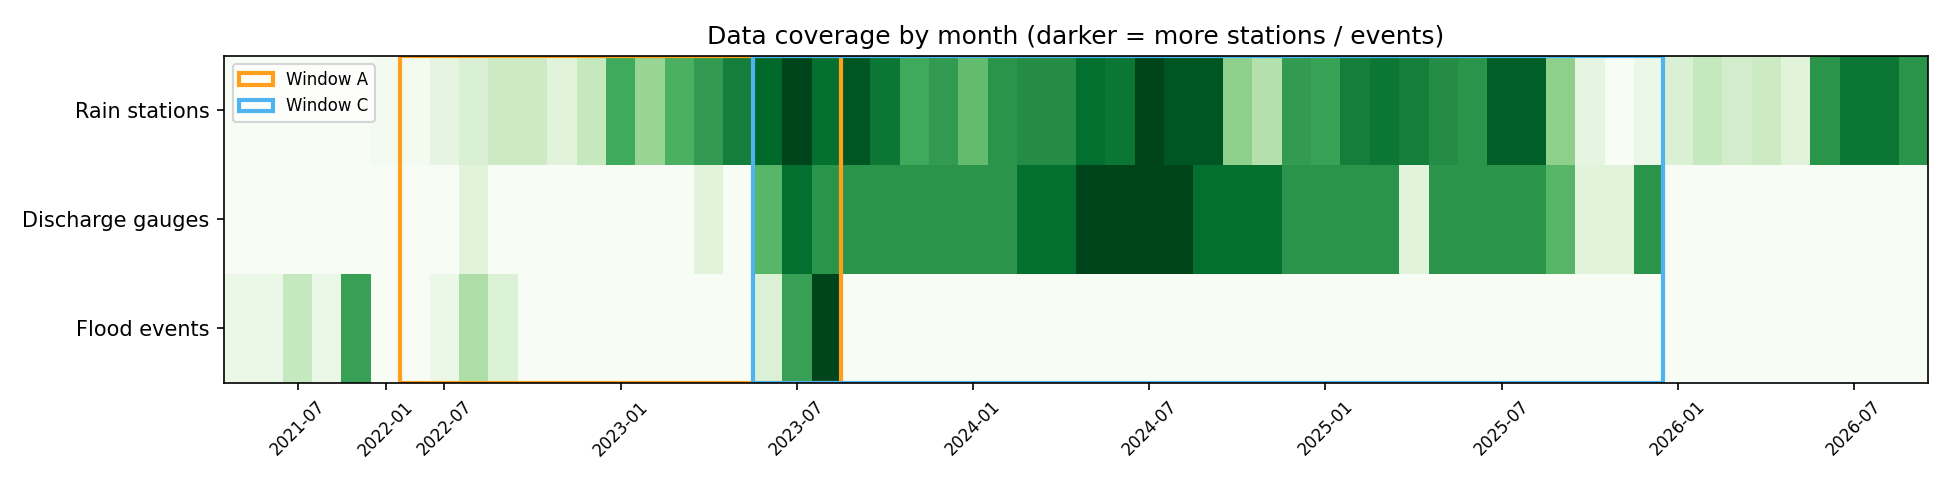

,start,end,sources,used_for
A_train_window,2022-02-01,2023-08-25,rainfall + labels (+ discharge where present),training / validation / test
B_all_sources,2023-06-07,2023-08-25,rainfall + discharge + labels,reported only (too short to train)
C_sensor_overlap,2023-06-07,2025-12-31,rainfall + discharge (labels need curation),replay now; training after label curation
replay,2023-08-26,None,NaN,inference / replay only (unlabelled)


In [3]:
from src.data_window import run as coverage_run
cov, windows = coverage_run()
display(Image(filename='results/data_audit/coverage_heatmap.png'))
pd.DataFrame(windows).T

## 3. Data contract tests

In [4]:
r = subprocess.run([sys.executable, '-m', 'pytest', '-q', 'tests/test_data.py'], capture_output=True, text=True)
print(r.stdout[-2000:]); assert r.returncode == 0, 'data tests failed'

............                                                             [100%]
12 passed in 2.81s



## 4. Train / validation / test partition (recorded once in results/splits.json)

In [5]:
from src.data_loader import load_ml_dataset
from src.split import get_chronological_splits
train_df, val_df, test_df = get_chronological_splits(load_ml_dataset())
pd.DataFrame(json.loads(Path('results/splits.json').read_text())).T

,start,end,rows,positives,stations,train_end,val_end,study_start,unlabelled_rows_excluded
train,2022-06-21 19:00:00,2023-06-30 23:00:00,94154,271,37,NaN,NaN,NaN,NaN
validation,2023-07-01 00:00:00,2023-07-31 23:00:00,20280,384,35,NaN,NaN,NaN,NaN
test,2023-08-01 00:00:00,2023-08-25 23:00:00,12469,240,29,NaN,NaN,NaN,NaN
rule,NaN,NaN,NaN,NaN,NaN,2023-07-01,2023-08-01,2022-02-01,True


## 5. Normalisation parameters (fitted on the training split only)

In [6]:
from src.data_loader import FEATURE_EXPERIMENTS, FINAL_EXPERIMENT
from src.preprocessing import get_tree_preprocessor
feats = FEATURE_EXPERIMENTS[FINAL_EXPERIMENT]
pre = get_tree_preprocessor().fit(train_df[feats])
s = json.loads(Path('results/splits.json').read_text())['train']
pre['normalizer'].to_json(Path('results/preprocessing/normalization_params.json'), fit_window={'start': s['start'], 'end': s['end']})
pd.DataFrame(pre['normalizer'].params_).round(4)

,feature,method,center,scale
0,rain_1h,log_robust,0.0000,0.4734
1,rain_3h,log_robust,0.0000,0.7305
2,rain_6h,log_robust,0.0000,0.9322
3,rain_12h,log_robust,0.0000,0.4055
4,rain_24h,log_robust,0.0000,1.3863
5,rain_48h,log_robust,0.0000,2.4423
6,rain_72h,log_robust,0.6931,3.1355
7,rain_max_intensity_24h,log_robust,0.0000,0.4055
8,rain_intensity_change_1h,signed_log,0.0000,0.3900
9,api_decay_85,log_robust,0.0000,0.5400
